# Trip EDA and Data Cleaning on Managed Apache Spark

Piazza Requirement 3 for the rideshare trips: all 628,189,680 trips (Nov 2018 – Aug 2026) checked in parallel by `src/eda/trip_eda.py`, run on Managed Apache Spark (Dataproc Serverless) as batch `hshah82-trip-eda-1123b`. The job writes small summary tables to `results/eda_trips/`; this notebook only plots them, so it runs in seconds on a laptop.

The earlier notebooks `01_data_quality_full.ipynb` and `03_trip_eda.ipynb` did the first version of these checks locally.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RES = ROOT / "results" / "eda_trips"
FIGS = ROOT / "docs" / "figures" / "eda"
FIGS.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9aa5b1"

diag = pd.read_csv(RES / "diagnostics.csv")
stats = pd.read_csv(RES / "stats.csv")
outl = pd.read_csv(RES / "outliers.csv")
hist = pd.read_csv(RES / "histograms.csv")
month = pd.read_csv(RES / "categories_by_month.csv")
dowh = pd.read_csv(RES / "categories_by_dow_hour.csv")
area = pd.read_csv(RES / "categories_by_pickup_area.csv")
names = pd.read_csv(ROOT / "results" / "cta_access_by_area.csv").set_index("area")["name"].replace({"Ohare": "O'Hare"})
total = int(diag.loc[diag.check == "rows", "rows"].iloc[0])
print(f"trips: {total:,}")

trips: 628,189,680


## 1. Diagnostics: missing values, duplicates, format problems

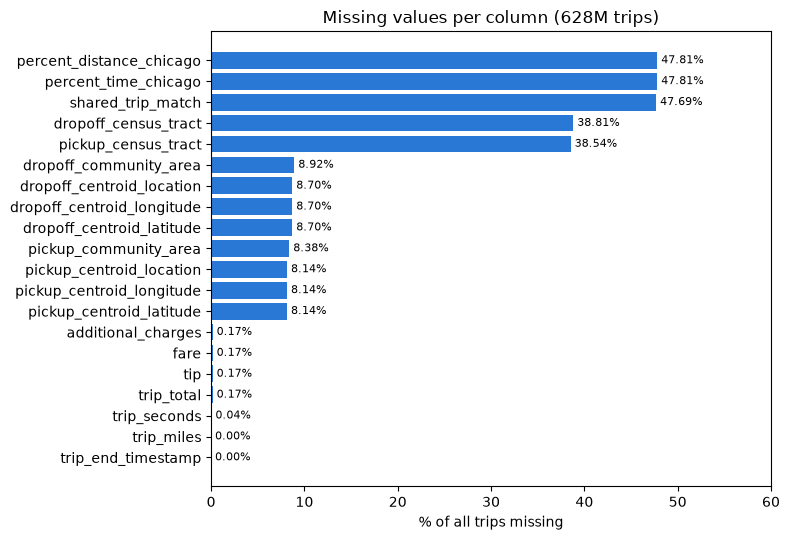

,kind,check,rows,pct
0,format,rows,628189680,100.0000
1,format,end before start,228072,0.0363
2,format,seconds <= 0,1989,0.0003
3,format,miles <= 0,201123,0.0320
4,format,over 4 hours,8312,0.0013
5,format,over 100 miles,140325,0.0223
6,format,fare <= 0,3817627,0.6077
7,format,fare over 500,1074,0.0002
8,format,total differs from fare+tip+charges by > $1,0,0.0000
9,format,percent_time_chicago > 1,114578,0.0182


In [2]:
miss = diag[(diag.kind == "missing") & (diag.rows > 0)].sort_values("pct")
plt.figure(figsize=(8, 5.5))
plt.barh(miss["check"], miss["pct"], color=BLUE)
for i, v in enumerate(miss["pct"]):
    plt.text(v, i, f" {v:.2f}%", va="center", fontsize=8)
plt.xlabel("% of all trips missing")
plt.title("Missing values per column (628M trips)")
plt.xlim(0, 60)
plt.tight_layout()
plt.savefig(FIGS / "trips_missing.png", dpi=150, bbox_inches="tight")
plt.show()
diag[diag.kind != "missing"]

Only location and the three columns added in 2023 have many gaps. 38–39% of trips have no census tract (the City hides tracts when few trips share them), but only 8.4% have no pickup community area, so we analyze by community area. `percent_time_chicago`, `percent_distance_chicago` and `shared_trip_match` are missing for 47.8% because the 2018–2022 table does not have them. Fare, tip and total are missing for 0.17%. There are no duplicate trip IDs, every community area is between 1 and 77, every pickup point is inside the Chicago area, and `trip_total` always equals fare + tip + additional charges (within $1).

## 2. Descriptive statistics

In [3]:
stats.set_index("feature").round(2)

,count,mean,std,min,p01,q1,median,q3,p99,max,skewness
feature,,,,,,,,,,,
trip_seconds,627960198,1117.33,806.03,0.0,171.0,553.00,900.00,1452.00,3870.00,86130.00,2.21
trip_miles,628182553,6.88,7.68,0.0,0.5,2.00,4.10,9.00,34.60,1881.90,3.97
fare,627129262,15.87,13.08,0.0,2.5,7.50,12.50,20.00,65.00,6145.00,3.62
tip,627129370,1.09,2.72,0.0,0.0,0.00,0.00,0.00,13.00,500.00,4.67
additional_charges,627129261,4.69,4.54,0.0,0.0,2.55,3.10,5.67,22.98,1658.84,5.28
trip_total,627129250,21.65,16.83,0.0,5.0,11.20,16.23,25.94,83.52,6197.97,3.21
trips_pooled,628189680,1.08,0.55,1.0,1.0,1.00,1.00,1.00,3.00,4097.00,2643.42
percent_time_chicago,327836628,0.93,0.58,0.0,0.0,1.00,1.00,1.00,1.00,4208.00,3815.21
percent_distance_chicago,327824967,0.92,0.28,0.0,0.0,1.00,1.00,1.00,1.00,941.00,345.93


Every money and distance feature is strongly right-skewed (skewness 2.2 to 5.3): the median trip is 15 minutes (900 s), 4.1 miles and a $12.50 fare, while the means are higher (18.6 minutes, 6.9 miles, $15.87). The maximum values are impossible for a single city ride (23.9 hours, 1,881.9 miles, a $6,145 fare, `trips_pooled` = 4,097, `percent_time_chicago` = 4,208). The quartiles are round numbers because the City rounds fares to the nearest $2.50 and tips to the nearest $1.00 for privacy, so the median tip is $0.

## 3. Distributions

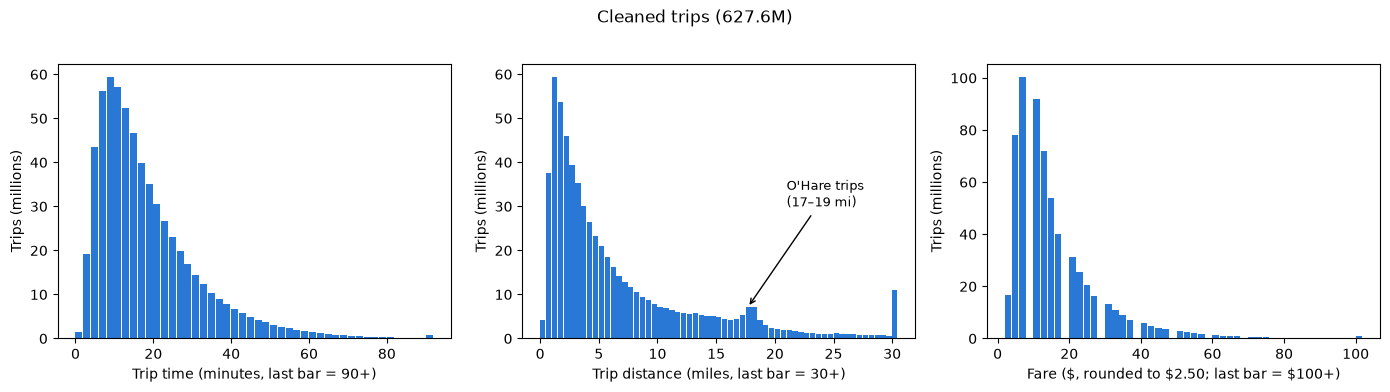

under 30 min: 84.1%   under 5 miles: 56.6%   17-19 miles: 3.8%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (var, label, width) in zip(axes, [("minutes", "Trip time (minutes, last bar = 90+)", 2),
                                          ("miles", "Trip distance (miles, last bar = 30+)", 0.5),
                                          ("fare", "Fare ($, rounded to $2.50; last bar = $100+)", 2)]):
    h = hist[hist["var"] == var]
    ax.bar(h["bin"], h["count"] / 1e6, width=width * 0.9, align="edge", color=BLUE)
    ax.set_xlabel(label)
    ax.set_ylabel("Trips (millions)")
axes[1].annotate("O'Hare trips\n(17–19 mi)", xy=(17.7, 7.1), xytext=(21, 30),
                 arrowprops=dict(arrowstyle="->"), fontsize=9)
fig.suptitle("Cleaned trips (627.6M)", y=1.02)
plt.tight_layout()
plt.savefig(FIGS / "trips_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

def share(var, cond):
    h = hist[hist["var"] == var]
    return 100 * h.loc[cond(h["bin"]), "count"].sum() / h["count"].sum()
print(f"under 30 min: {share('minutes', lambda b: b < 30):.1f}%   under 5 miles: {share('miles', lambda b: b < 5):.1f}%   "
      f"17-19 miles: {share('miles', lambda b: (b >= 17) & (b < 19)):.1f}%")

Most trips are short: 84% take under 30 minutes and 57% are under 5 miles, with the most common trip 1–1.5 miles and 8–10 minutes. There is a second bump at 17–19 miles (3.8% of trips), the distance from downtown to O'Hare. The fare chart has gaps every $10 (no bars at $8, $18, $28, …) because fares are published in $2.50 steps, which fall into only four of every five $2 bins.

## 4. When people ride

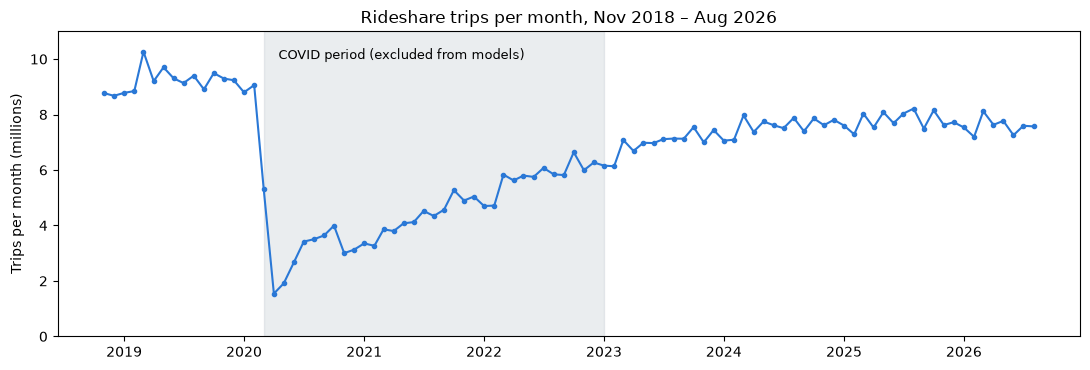

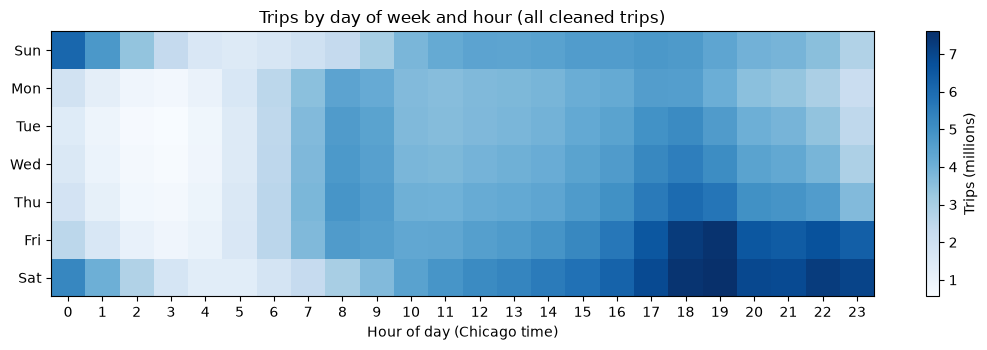

In [5]:
m = month.assign(date=pd.to_datetime(month["year_month"]))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(m["date"], m["count"] / 1e6, color=BLUE, marker="o", ms=3)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2022-12-31"), color=GREY, alpha=0.2)
ax.text(pd.Timestamp("2020-04-15"), 10, "COVID period (excluded from models)", fontsize=9)
ax.set_ylabel("Trips per month (millions)")
ax.set_ylim(0, 11)
ax.set_title("Rideshare trips per month, Nov 2018 – Aug 2026")
plt.tight_layout()
plt.savefig(FIGS / "trips_per_month.png", dpi=150, bbox_inches="tight")
plt.show()

grid = dowh.pivot(index="dow", columns="hour", values="count") / 1e6
grid.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(grid.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(24), [str(h) for h in range(24)])
ax.set_yticks(range(7), grid.index)
ax.set_xlabel("Hour of day (Chicago time)")
plt.colorbar(im, label="Trips (millions)")
ax.set_title("Trips by day of week and hour (all cleaned trips)")
plt.tight_layout()
plt.savefig(FIGS / "trips_dow_hour.png", dpi=150, bbox_inches="tight")
plt.show()

Before COVID, Chicago had about 9.3 million rideshare trips a month (peak: 10.3 million in March 2019). April 2020 fell to 1.5 million, 83% below April 2019. Trips recovered slowly and have been flat at about 7.2–8.2 million a month since 2024, still below 2019. Weekdays have a morning peak at 8 AM and a bigger evening peak at 5–6 PM; Friday and Saturday evenings are the busiest hours of the week (about 7.5 million trips each at 7 PM), and Friday and Saturday nights stay busy past midnight (the dark cells at 0–1 AM on Saturday and Sunday). The quietest hour is 3 AM on a Tuesday.

## 5. Where trips start

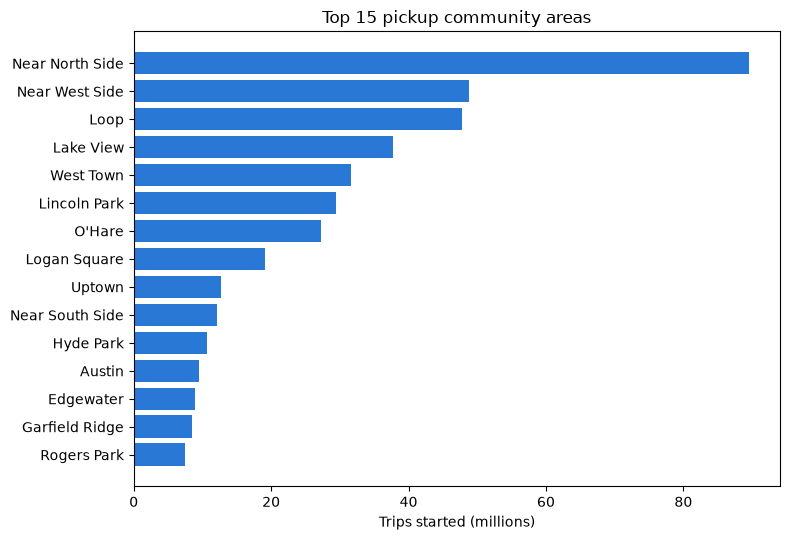

top 5 areas: 44.5% of trips with a known area; bottom 38 areas: 10.1%


,area,count,name
74,74,582139,Mount Greenwood
37,37,578695,Fuller Park
52,52,397176,East Side
47,47,342457,Burnside
55,55,328773,Hegewisch


In [6]:
a = area.dropna().astype({"area": int})
a["name"] = a["area"].map(names)
a = a.sort_values("count", ascending=False)
top = a.head(15).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top["name"], top["count"] / 1e6, color=BLUE)
plt.xlabel("Trips started (millions)")
plt.title("Top 15 pickup community areas")
plt.tight_layout()
plt.savefig(FIGS / "trips_top_areas.png", dpi=150, bbox_inches="tight")
plt.show()
cl = a["count"].sum()
print(f"top 5 areas: {100 * a.head(5)['count'].sum() / cl:.1f}% of trips with a known area; "
      f"bottom 38 areas: {100 * a.tail(38)['count'].sum() / cl:.1f}%")
a.tail(5)

Trips are concentrated: the Near North Side alone starts 89.6 million trips, and the top 5 areas (Near North Side, Near West Side, Loop, Lake View, West Town) start 44% of all trips with a known area, while the 38 least-used areas together start 10%. The smallest counts are on the Far South Side (Hegewisch, Burnside, East Side, all under 0.4 million). Raw counts mostly reflect where people and jobs are, which is why the transit-gap score uses trips per person.

## 6. Outliers: IQR rule vs z-scores

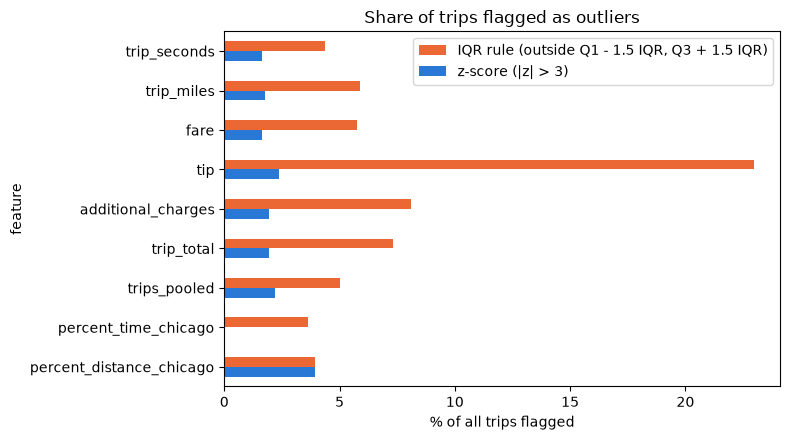

,feature,iqr_low,iqr_high,iqr_outliers,iqr_pct,z_low,z_high,z_outliers,z_pct
0,trip_seconds,-795.50,2800.50,27331737,4.35,-1300.77,3535.44,10154628,1.62
1,trip_miles,-8.50,19.50,36838947,5.86,-16.17,29.92,11204522,1.78
2,fare,-11.25,38.75,36254362,5.77,-23.36,55.10,10385480,1.65
3,tip,0.00,0.00,144196398,22.95,-7.06,9.24,14930370,2.38
4,additional_charges,-2.13,10.35,50963598,8.11,-8.93,18.31,12275941,1.95
5,trip_total,-10.91,48.05,45897033,7.31,-28.86,72.15,12064016,1.92
6,trips_pooled,1.00,1.00,31539346,5.02,-0.56,2.73,13806567,2.20
7,percent_time_chicago,1.00,1.00,22737392,3.62,-0.82,2.68,33095,0.00
8,percent_distance_chicago,1.00,1.00,24789882,3.95,0.07,1.77,24789882,3.95


In [7]:
o = outl.set_index("feature")[["iqr_pct", "z_pct"]]
ax = o.plot(kind="barh", figsize=(8, 4.5), color=[ORANGE, BLUE])
ax.set_xlabel("% of all trips flagged")
ax.legend(["IQR rule (outside Q1 - 1.5 IQR, Q3 + 1.5 IQR)", "z-score (|z| > 3)"])
ax.set_title("Share of trips flagged as outliers")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIGS / "trips_outliers.png", dpi=150, bbox_inches="tight")
plt.show()
outl.round(2)

On skewed data the two rules disagree a lot. The IQR rule flags 4–6% of trips for time, distance and fare (every trip over 46.7 minutes or 19.5 miles), which would remove all O'Hare trips, and it flags every tip above $0 (23% of trips) because more than three quarters of trips have no tip. The z-score rule flags fewer trips (1.6–1.8%) but its bounds still come from the extreme values. Neither rule finds errors: they find long, real trips. We therefore keep statistical outliers and remove only impossible values (see the cleaning rules in `EDA.md`).